In [3]:
from google.colab import auth
auth.authenticate_user()

from google.cloud import bigquery
client = bigquery.Client(project="bigquery-datascientist")

df = client.query("""
    select * from `bigquery-datascientist.dbt_zeynep.fct_category_revenue`
""").to_dataframe()
df.head()

,category,gross_revenue,cancelled_revenue,returned_revenue,net_revenue,items_sold
0,Active,446649.51,66368.05,43424.91,336856.55,6740
1,Maternity,266550.35,38500.40,26187.72,201862.23,3871
2,Sweaters,839936.77,121602.30,81356.87,636977.60,8483
3,Swim,644413.71,101737.31,63921.99,478754.41,8398
4,Suits & Sport Coats,601417.31,89211.21,59646.86,452559.24,3619


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   category           26 non-null     object 
 1   gross_revenue      26 non-null     float64
 2   cancelled_revenue  26 non-null     float64
 3   returned_revenue   26 non-null     float64
 4   net_revenue        26 non-null     float64
 5   items_sold         26 non-null     Int64  
dtypes: Int64(1), float64(4), object(1)
memory usage: 1.4+ KB


In [ ]:
df.describe()

,gross_revenue,cancelled_revenue,returned_revenue,net_revenue,items_sold
count,2.600000e+01,26.000000,26.000000,2.600000e+01,26.0
mean,4.151980e+05,62544.519615,40763.033462,3.118904e+05,5241.692308
std,3.392405e+05,51660.305738,32919.475216,2.548586e+05,3098.989484
min,1.809079e+04,2691.040000,1733.610000,1.366614e+04,161.0
25%,1.362946e+05,23132.595000,13506.635000,1.041552e+05,2680.75
50%,4.274895e+05,63103.885000,42395.975000,3.200601e+05,5030.0
75%,5.382232e+05,79423.840000,53183.870000,4.057766e+05,8355.5
max,1.327472e+06,204141.610000,127748.210000,1.003876e+06,10362.0


In [ ]:
df['avg_item_price'] = df['net_revenue'] / df['items_sold']
#df['loss_amount'] = df['cancelled_revenue'] + df['returned_revenue']
df['loss_rate'] = ((df['cancelled_revenue'] + df['returned_revenue'])/ df['gross_revenue']) * 100

df.head()

,category,gross_revenue,cancelled_revenue,returned_revenue,net_revenue,items_sold,avg_item_price,loss_rate
0,Active,446649.51,66368.05,43424.91,336856.55,6740,49.978717,24.581458
1,Maternity,266550.35,38500.40,26187.72,201862.23,3871,52.147308,24.268631
2,Sweaters,839936.77,121602.30,81356.87,636977.60,8483,75.088719,24.163625
3,Swim,644413.71,101737.31,63921.99,478754.41,8398,57.008146,25.706979
4,Suits & Sport Coats,601417.31,89211.21,59646.86,452559.24,3619,125.050909,24.751211


In [ ]:
top_10 = df.sort_values(by='net_revenue', ascending=False).head(10)
top_10 = top_10.sort_values(by='net_revenue', ascending=True)

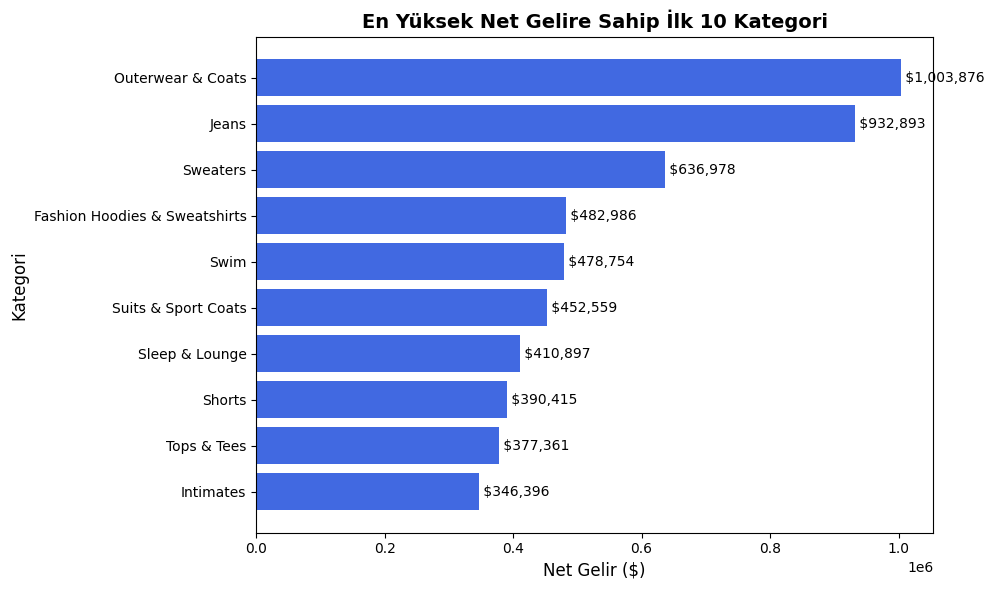

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.barh(top_10['category'], top_10['net_revenue'], color='royalblue')

plt.title('En Yüksek Net Gelire Sahip İlk 10 Kategori', fontsize=14, fontweight='bold')
plt.xlabel('Net Gelir ($)', fontsize=12)
plt.ylabel('Kategori', fontsize=12)

for index, value in enumerate(top_10['net_revenue']):
    plt.text(value, index, f" ${value:,.0f}", va='center')

plt.tight_layout()
plt.show()

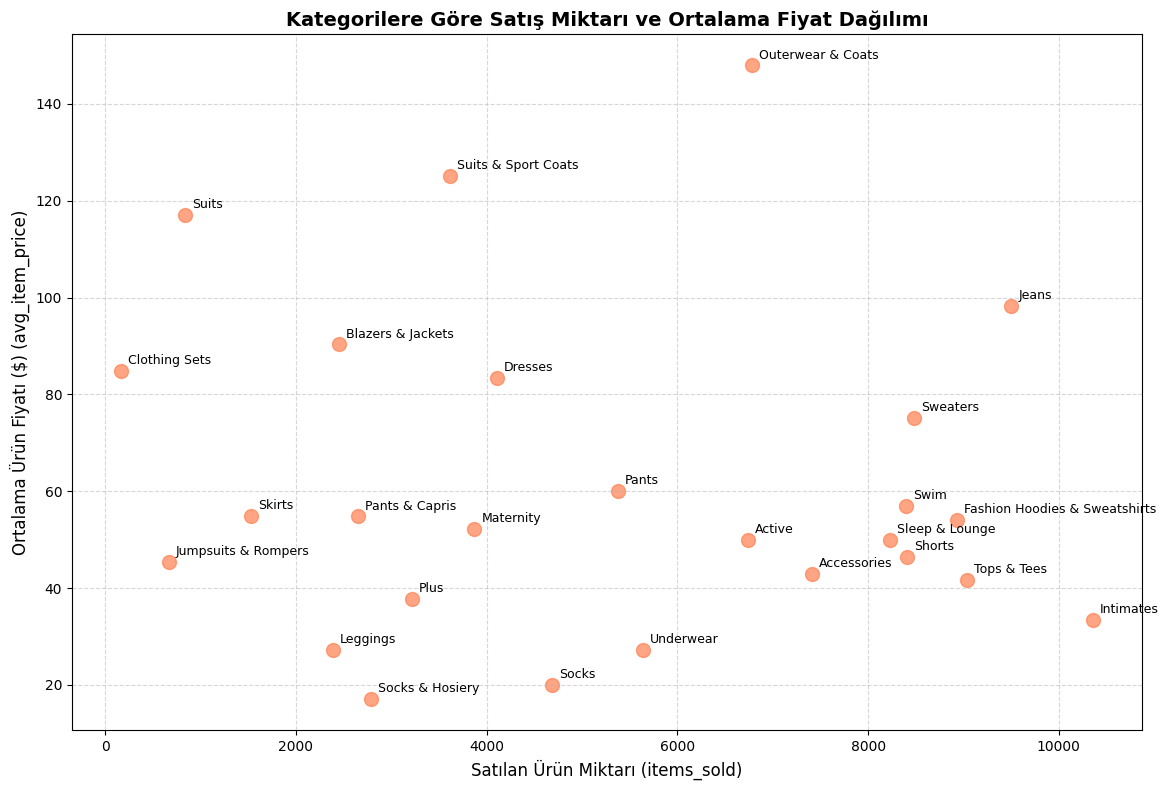

In [ ]:
plt.figure(figsize=(12, 8))

plt.scatter(df['items_sold'], df['avg_item_price'], color='coral', alpha=0.7, s=100)

for index, row in df.iterrows():
    plt.annotate(
        row['category'],
        (row['items_sold'], row['avg_item_price']),
        textcoords="offset points",
        xytext=(5, 5),
        ha='left',
        fontsize=9
    )

plt.title('Kategorilere Göre Satış Miktarı ve Ortalama Fiyat Dağılımı', fontsize=14, fontweight='bold')
plt.xlabel('Satılan Ürün Miktarı (items_sold)', fontsize=12)
plt.ylabel('Ortalama Ürün Fiyatı ($) (avg_item_price)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Mobile Games A/B Testing - Cookie Cats

In [ ]:
from google.colab import files
import pandas as pd

ab = pd.read_csv('/content/drive/MyDrive/data sciencist/cookie_cats.csv')
ab.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [ ]:
ab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB


In [ ]:
ab.describe()

,userid,sum_gamerounds
count,9.018900e+04,90189.000000
mean,4.998412e+06,51.872457
std,2.883286e+06,195.050858
min,1.160000e+02,0.000000
25%,2.512230e+06,5.000000
50%,4.995815e+06,16.000000
75%,7.496452e+06,51.000000
max,9.999861e+06,49854.000000


In [ ]:
count = len(ab[ab['version'] == 'gate_30'])
print(f"gate_30 versiyonunun sayısı: {count}")

gate_30 versiyonunun sayısı: 44700


In [ ]:
count = len(ab[ab['version'] == 'gate_40'])
print(f"gate_40 versiyonunun sayısı: {count}")

gate_40 versiyonunun sayısı: 45489


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

--- İstatistiksel Özet ---
count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64




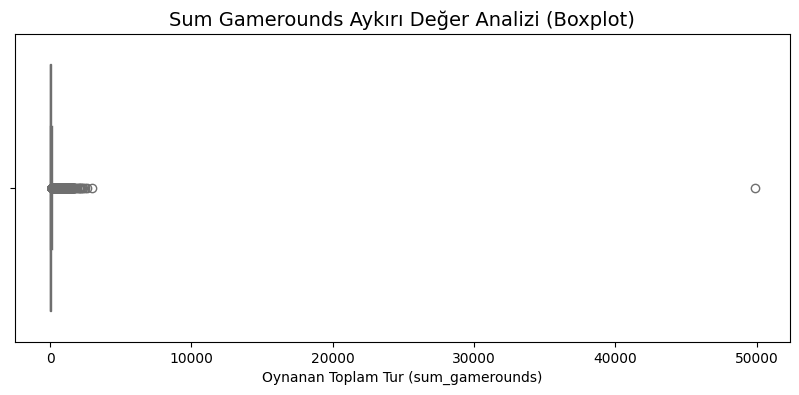

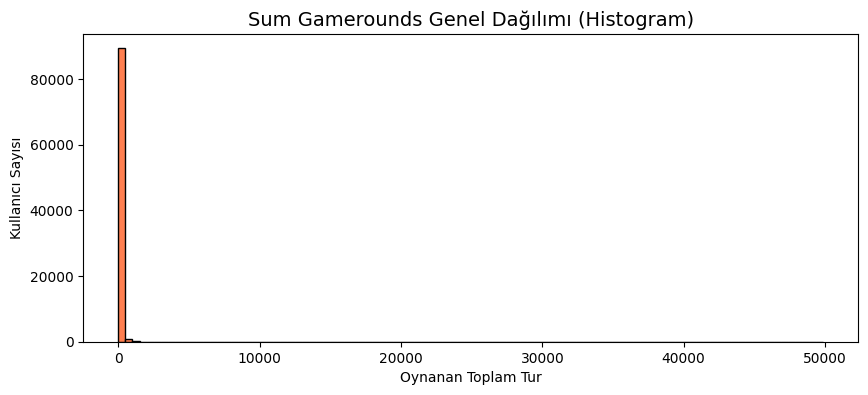

Veri setindeki en yüksek oynama sayısı: 49854


In [ ]:
print("--- İstatistiksel Özet ---")
print(ab['sum_gamerounds'].describe())
print("\n")

plt.figure(figsize=(10, 4))
sns.boxplot(x=ab['sum_gamerounds'], color='skyblue')
plt.title('Sum Gamerounds Aykırı Değer Analizi (Boxplot)', fontsize=14)
plt.xlabel('Oynanan Toplam Tur (sum_gamerounds)')
plt.show()


plt.figure(figsize=(10, 4))
plt.hist(ab['sum_gamerounds'], bins=100, color='coral', edgecolor='black')
plt.title('Sum Gamerounds Genel Dağılımı (Histogram)', fontsize=14)
plt.xlabel('Oynanan Toplam Tur')
plt.ylabel('Kullanıcı Sayısı')
plt.show()

max_deger = ab['sum_gamerounds'].max()
print(f"Veri setindeki en yüksek oynama sayısı: {max_deger}")

In [ ]:
retention_ozet = ab.groupby('version')[['retention_1', 'retention_7']].mean()

print("--- Retention (Elde Tutma) Oranları ---")
print(retention_ozet * 100)

--- Retention (Elde Tutma) Oranları ---
         retention_1  retention_7
version                          
gate_30    44.818792    19.020134
gate_40    44.228275    18.200004


In [ ]:
from statsmodels.stats.proportion import proportions_ztest

# 1. Gün (retention_1) için başarı (True) ve toplam gözlem sayıları
success_1 = [ab[ab['version'] == 'gate_30']['retention_1'].sum(),
             ab[ab['version'] == 'gate_40']['retention_1'].sum()]
nobs_1 = [ab[ab['version'] == 'gate_30']['retention_1'].count(),
          ab[ab['version'] == 'gate_40']['retention_1'].count()]

# 7. Gün (retention_7) için başarı (True) ve toplam gözlem sayıları
success_7 = [ab[ab['version'] == 'gate_30']['retention_7'].sum(),
             ab[ab['version'] == 'gate_40']['retention_7'].sum()]
nobs_7 = [ab[ab['version'] == 'gate_30']['retention_7'].count(),
          ab[ab['version'] == 'gate_40']['retention_7'].count()]

# Z-Testi hesaplamaları
z_stat_1, p_val_1 = proportions_ztest(success_1, nobs_1)
z_stat_7, p_val_7 = proportions_ztest(success_7, nobs_7)

print(f"1. Gün Retention P-Değeri: {p_val_1:.4f}")
print(f"7. Gün Retention P-Değeri: {p_val_7:.4f}")

1. Gün Retention P-Değeri: 0.0744
7. Gün Retention P-Değeri: 0.0016


In [9]:

query = """
WITH customer_features AS (
    SELECT
        user_id,
        COUNT(DISTINCT order_id) AS siparis_sayisi,
        SUM(sale_price) AS toplam_harcama,
        DATE_DIFF(DATE('2025-07-01'), DATE(MIN(created_at)), DAY) AS ilk_siparisten_kesime_gun,
        DATE_DIFF(DATE('2025-07-01'), DATE(MAX(created_at)), DAY) AS recency
    FROM
        `bigquery-public-data.thelook_ecommerce.order_items`
    WHERE
        DATE(created_at) < '2025-07-01'
    GROUP BY
        user_id
),

target_period AS (
    SELECT DISTINCT
        user_id,
        1 AS active_in_target
    FROM
        `bigquery-public-data.thelook_ecommerce.order_items`
    WHERE
        DATE(created_at) BETWEEN '2025-07-01' AND '2025-09-28'
)

SELECT
    f.user_id,
    f.siparis_sayisi,
    f.toplam_harcama,
    f.ilk_siparisten_kesime_gun,
    f.recency,
    CASE
        WHEN t.active_in_target IS NULL THEN 1
        ELSE 0
    END AS churn
FROM
    customer_features f
LEFT JOIN
    target_period t ON f.user_id = t.user_id
"""

churn_df = client.query(query).to_dataframe()
display(churn_df.head())


,user_id,siparis_sayisi,toplam_harcama,ilk_siparisten_kesime_gun,recency,churn
0,86871,1,0.020000,251,251,1
1,9641,1,0.490000,825,825,1
2,53753,1,0.490000,536,536,1
3,2794,1,186.410003,385,382,1
4,38565,1,31.460001,1410,1408,1


In [10]:

query_filtered = """
WITH customer_features AS (
    SELECT
        user_id,
        COUNT(DISTINCT order_id) AS siparis_sayisi,
        SUM(sale_price) AS toplam_harcama,
        DATE_DIFF(DATE('2025-07-01'), DATE(MIN(created_at)), DAY) AS ilk_siparisten_kesime_gun,
        DATE_DIFF(DATE('2025-07-01'), DATE(MAX(created_at)), DAY) AS recency
    FROM
        `bigquery-public-data.thelook_ecommerce.order_items`
    WHERE
        DATE(created_at) < '2025-07-01'
        AND status NOT IN ('Cancelled', 'Returned')
    GROUP BY
        user_id
),

target_period AS (
    SELECT DISTINCT
        user_id,
        1 AS active_in_target
    FROM
        `bigquery-public-data.thelook_ecommerce.order_items`
    WHERE
        DATE(created_at) BETWEEN '2025-07-01' AND '2025-09-28'
        AND status NOT IN ('Cancelled', 'Returned')
)

SELECT
    f.user_id,
    f.siparis_sayisi,
    f.toplam_harcama,
    f.ilk_siparisten_kesime_gun,
    f.recency,
    CASE
        WHEN t.active_in_target IS NULL THEN 1
        ELSE 0
    END AS churn
FROM
    customer_features f
LEFT JOIN
    target_period t ON f.user_id = t.user_id
"""


churn_df = client.query(query_filtered).to_dataframe()


In [11]:

print("--- Filtreleme Öncesi Churn Oranları ---")
display(churn_df['churn'].value_counts(normalize=True) * 100)


--- Filtreleme Öncesi Churn Oranları ---


,proportion
churn,
1,95.632451
0,4.367549


In [12]:

active_churn_df = churn_df[churn_df['recency'] <= 365].copy()

print("--- Son 1 Yılda Alışveriş Yapmış Aktif Müşteriler İçin Churn Oranları ---")
display(active_churn_df['churn'].value_counts(normalize=True) * 100)
print(f"\nToplam Aktif Müşteri Sayısı: {len(active_churn_df)}")


--- Son 1 Yılda Alışveriş Yapmış Aktif Müşteriler İçin Churn Oranları ---


,proportion
churn,
1,94.113888
0,5.886112



Toplam Aktif Müşteri Sayısı: 15647


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report

X = churn_df[['siparis_sayisi','toplam_harcama','ilk_siparisten_kesime_gun','recency']]
y = churn_df['churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [16]:



model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]


roc_auc = roc_auc_score(y_test, y_pred_proba)
class_report = classification_report(y_test, y_pred)


print(f"Test Seti ROC AUC Skoru: {roc_auc:.4f}\n")
print("Test Seti Sınıflandırma Raporu:")
print(class_report)


Test Seti ROC AUC Skoru: 0.5943

Test Seti Sınıflandırma Raporu:
              precision    recall  f1-score   support

         0.0       0.00      0.00      0.00       331
         1.0       0.96      1.00      0.98      7253

    accuracy                           0.96      7584
   macro avg       0.48      0.50      0.49      7584
weighted avg       0.91      0.96      0.94      7584



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [17]:

X_active = active_churn_df[['siparis_sayisi', 'toplam_harcama', 'ilk_siparisten_kesime_gun', 'recency']]
y_active = active_churn_df['churn'].astype(int)


X_train_act, X_test_act, y_train_act, y_test_act = train_test_split(
    X_active, y_active, test_size=0.2, stratify=y_active, random_state=42
)


model_active = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model_active.fit(X_train_act, y_train_act)


y_pred_act = model_active.predict(X_test_act)
y_pred_proba_act = model_active.predict_proba(X_test_act)[:, 1]


roc_auc_act = roc_auc_score(y_test_act, y_pred_proba_act)
class_report_act = classification_report(y_test_act, y_pred_act)

print(f"Aktif Müşteriler için Test Seti ROC AUC Skoru: {roc_auc_act:.4f}\n")
print("Aktif Müşteriler için Sınıflandırma Raporu:")
print(class_report_act)


Aktif Müşteriler için Test Seti ROC AUC Skoru: 0.5892

Aktif Müşteriler için Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       0.07      0.63      0.13       184
           1       0.96      0.50      0.66      2946

    accuracy                           0.51      3130
   macro avg       0.51      0.56      0.39      3130
weighted avg       0.90      0.51      0.63      3130



In [18]:
query_with_user_features = """
WITH customer_features AS (
    SELECT
        user_id,
        COUNT(DISTINCT order_id) AS siparis_sayisi,
        SUM(sale_price) AS toplam_harcama,
        DATE_DIFF(DATE('2025-07-01'), DATE(MIN(created_at)), DAY) AS ilk_siparisten_kesime_gun,
        DATE_DIFF(DATE('2025-07-01'), DATE(MAX(created_at)), DAY) AS recency
    FROM
        `bigquery-public-data.thelook_ecommerce.order_items`
    WHERE
        DATE(created_at) < '2025-07-01'
        AND status NOT IN ('Cancelled', 'Returned')
    GROUP BY
        user_id
),

target_period AS (
    SELECT DISTINCT
        user_id,
        1 AS active_in_target
    FROM
        `bigquery-public-data.thelook_ecommerce.order_items`
    WHERE
        DATE(created_at) BETWEEN '2025-07-01' AND '2025-09-28'
        AND status NOT IN ('Cancelled', 'Returned')
)

SELECT
    f.user_id,
    f.siparis_sayisi,
    f.toplam_harcama,
    f.ilk_siparisten_kesime_gun,
    f.recency,
    u.age,
    u.gender,
    u.traffic_source,
    CASE
        WHEN t.active_in_target IS NULL THEN 1
        ELSE 0
    END AS churn
FROM
    customer_features f
LEFT JOIN
    target_period t ON f.user_id = t.user_id
LEFT JOIN
    `bigquery-public-data.thelook_ecommerce.users` u ON f.user_id = u.id
"""


rich_df = client.query(query_with_user_features).to_dataframe()
display(rich_df.head())


,user_id,siparis_sayisi,toplam_harcama,ilk_siparisten_kesime_gun,recency,age,gender,traffic_source,churn
0,47635,1,38.930000,308,307,12,M,Search,1
1,60997,1,3.980000,1225,1225,12,M,Organic,1
2,71967,1,113.160000,1143,1142,12,F,Facebook,1
3,32673,1,4.100000,1542,1542,12,F,Organic,1
4,6642,2,97.860002,66,19,12,F,Search,1


In [21]:

import pandas as pd


rich_df['ortalama_sepet_tutari'] = rich_df['toplam_harcama'] / rich_df['siparis_sayisi']


rich_active_df = rich_df[rich_df['recency'] <= 365].copy()


categorical_cols = ['gender', 'traffic_source']
rich_active_encoded = pd.get_dummies(rich_active_df, columns=categorical_cols, drop_first=True)


feature_cols = [
    'siparis_sayisi', 'toplam_harcama', 'ortalama_sepet_tutari',
    'ilk_siparisten_kesime_gun', 'recency', 'age'
] + [col for col in rich_active_encoded.columns if col.startswith(('gender_', 'traffic_source_'))]

X_rich = rich_active_encoded[feature_cols]
y_rich = rich_active_encoded['churn'].astype(int)

display(X_rich.head())

,siparis_sayisi,toplam_harcama,ortalama_sepet_tutari,ilk_siparisten_kesime_gun,recency,age,gender_M,traffic_source_Email,traffic_source_Facebook,traffic_source_Organic,traffic_source_Search
0,1,38.930000,38.93,308,307,12,True,False,False,False,True
4,2,97.860002,48.930001,66,19,12,False,False,False,False,True
5,2,44.940001,22.470001,761,81,12,False,False,False,False,True
6,1,289.329999,289.329999,216,212,12,False,False,False,True,False
10,1,6.500000,6.5,176,176,12,True,False,False,False,True


In [22]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report


X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_rich, y_rich, test_size=0.2, stratify=y_rich, random_state=42
)


pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
)

pipeline.fit(X_train_r, y_train_r)


y_pred_r = pipeline.predict(X_test_r)
y_pred_proba_r = pipeline.predict_proba(X_test_r)[:, 1]


roc_auc_r = roc_auc_score(y_test_r, y_pred_proba_r)
print(f"Yeni Ölçekli & Zenginleştirilmiş Model ROC AUC Skoru: {roc_auc_r:.4f}\n")
print("Yeni Model Sınıflandırma Raporu:")
print(classification_report(y_test_r, y_pred_r))

Yeni Ölçekli & Zenginleştirilmiş Model ROC AUC Skoru: 0.5494

Yeni Model Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       0.07      0.58      0.12       184
           1       0.95      0.51      0.66      2946

    accuracy                           0.51      3130
   macro avg       0.51      0.54      0.39      3130
weighted avg       0.90      0.51      0.63      3130



--- Model Karşılaştırma Tablosu ---


,Model,ROC AUC Skoru
0,Logistic Regression (Pipeline),0.549448
1,Random Forest Classifier,0.532149



Random Forest Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       184
           1       0.94      1.00      0.97      2946

    accuracy                           0.94      3130
   macro avg       0.47      0.50      0.48      3130
weighted avg       0.89      0.94      0.91      3130



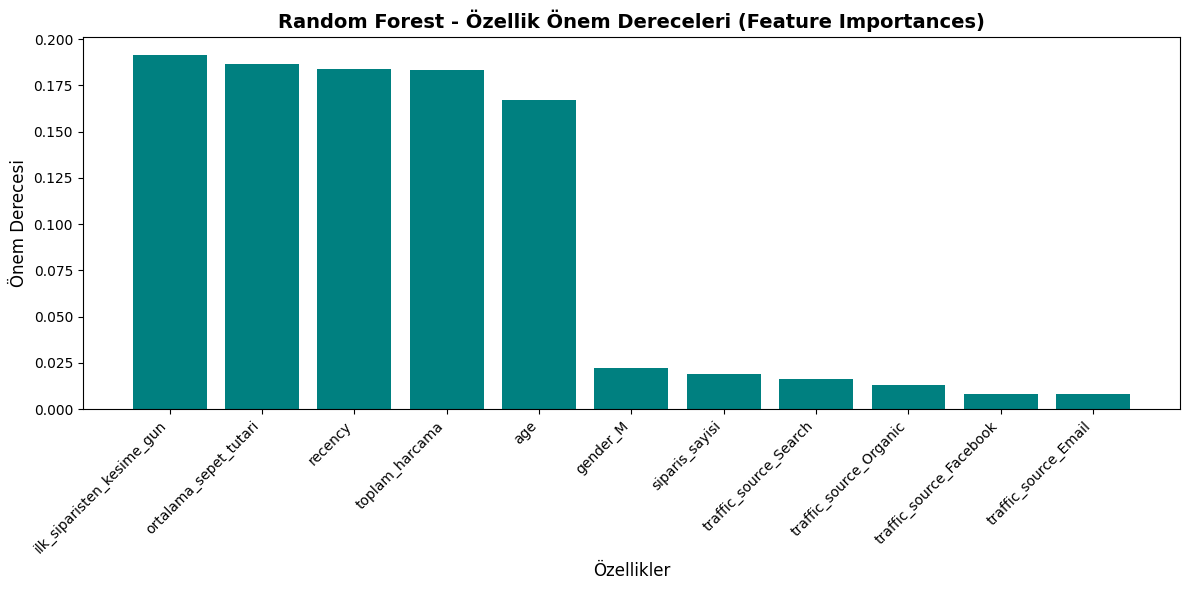

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report


rf_model = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)
rf_model.fit(X_train_r, y_train_r)


y_pred_rf = rf_model.predict(X_test_r)
y_pred_proba_rf = rf_model.predict_proba(X_test_r)[:, 1]


roc_auc_rf = roc_auc_score(y_test_r, y_pred_proba_rf)


comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression (Pipeline)', 'Random Forest Classifier'],
    'ROC AUC Skoru': [roc_auc_r, roc_auc_rf]
})

print("--- Model Karşılaştırma Tablosu ---")
display(comparison_df)
print("\nRandom Forest Sınıflandırma Raporu:")
print(classification_report(y_test_r, y_pred_rf))


importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]
features = X_rich.columns

plt.figure(figsize=(12, 6))
plt.bar(range(X_rich.shape[1]), importances[indices], color='teal', align='center')
plt.xticks(range(X_rich.shape[1]), [features[i] for i in indices], rotation=45, ha='right')
plt.title('Random Forest - Özellik Önem Dereceleri (Feature Importances)', fontsize=14, fontweight='bold')
plt.xlabel('Özellikler', fontsize=12)
plt.ylabel('Önem Derecesi', fontsize=12)
plt.tight_layout()
plt.show()

In [24]:
from sklearn.inspection import permutation_importance
r = permutation_importance(rf_model, X_test_r, y_test_r, scoring='roc_auc', n_repeats=10, random_state=42)